# Clasificación de muebles de exhibición a partir de fotografías de mercaderistas

**Proyecto de Machine Learning** · Sebastián Garzón · Maestría en Ciencia de Datos, USFQ

Cuaderno autocontenido: datos, análisis exploratorio, modelo por transfer learning, optimización de hiperparámetros
(sesgo y varianza según λ, curva de aprendizaje) con validación cruzada repetida, comparación estadística de dos
técnicas, visualización con t-SNE, evaluación en prueba y conclusiones. Corre en Google Colab con GPU (*Entorno de
ejecución → Ejecutar todas*).

| Sección | Ítem de la rúbrica |
|---|---|
| 1 | Introducción |
| 2–3 | EDA |
| 4–5 | Modelo (transfer learning) y Pipelines. Al ser un problema de imágenes con transfer learning, no se hace selección de características |
| 6 | Optimización de hiperparámetros: λ con Optuna y su curva de sesgo y varianza, tamaño m por la curva de aprendizaje |
| 7 | Comparación estadística de 2 técnicas |
| 8 | Visualización con t-SNE |
| 9 | Evaluación en prueba |
| 10 | Extensión: ajuste fino y despliegue en el teléfono |
| 11–12 | Conclusiones y referencias |

## 1. Introducción

Industrias Ales paga a las cadenas de autoservicio (Tía, Favorita, El Rosado, Santa María, Coral) por exhibir sus
productos en **muebles** contratados: chicleras, laterales, check outs, cabeceras y exhibidores de piso. Para
verificar que el mueble existe, un mercaderista visita cada local y envía una **fotografía como evidencia**. Hoy esa
verificación es manual y llega tarde: una foto oscura, de la percha regular en lugar del mueble, o de otra cosa, entra
a los tableros de cumplimiento como evidencia válida, y el mercaderista se entera cuando ya salió del local [1].

El objetivo es **clasificar automáticamente cada fotografía** en una de siete categorías, cinco tipos de mueble y dos
de rechazo, con un modelo que pueda correr en los teléfonos de gama baja de los mercaderistas:

| Clase | Qué muestra |
|---|---|
| chiclera, lateral, check_out, cabecera, exhibidor_piso | El mueble contratado |
| captura_invalida | Foto técnicamente inservible: oscura, negra, desenfocada, movida, al piso o al techo |
| contenido_ajeno | Foto legible de otra cosa: percha regular sin mueble, producto suelto, personas, pantallas |

Importa porque (a) la alerta en el dispositivo permite repetir la foto en el momento, (b) libera a los supervisores de
revisar decenas de miles de fotos al año, y (c) los convenios mueven dinero que depende de esa evidencia. El problema
es de **clasificación de imagen, multiclase, con fuerte desbalance**, y con un riesgo metodológico central: el mismo
local se fotografía cada mes, así que separar mal entrenamiento y prueba infla el desempeño [2]. Por eso toda la
validación de este cuaderno se **agrupa por local**.

## 0. Configuración

In [1]:
# Prompt (Claude Code): "estructura el proyecto con esta rúbrica en mente" -> configuración común Colab / local.
import os, subprocess, sys, json, time, warnings
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
RAPIDO = os.getenv("RAPIDO") == "1"  # validación local con una submuestra; en Colab siempre False
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/tesis")  # aquí debe estar tesis_colab.zip
    if not Path("/content/tesis/data/manifest.csv").exists():
        subprocess.run(f'cp "{DRIVE}/tesis_colab.zip" /content/ && unzip -q -o /content/tesis_colab.zip -d /content/tesis',
                       shell=True, check=True)
    os.chdir("/content/tesis")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna"], check=True)
    MANIFEST = "data/manifest.csv"
else:
    if Path.cwd().name == "notebooks":  # abierto desde la carpeta del cuaderno
        os.chdir("..")
    DRIVE = Path("data/proyecto_ml")
    if os.name == "nt":  # Windows: joblib cierra su carpeta de memoria compartida entre llamadas (WinError 6)
        from joblib import parallel_config
        parallel_config(max_nbytes=None)  # los datos viajan a cada proceso en lugar de compartirse
    MANIFEST = "data/manifest_320.csv"
CACHE = DRIVE / "rasgos"
CACHE.mkdir(parents=True, exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

CLASES = ["chiclera", "lateral", "check_out", "cabecera", "exhibidor_piso", "captura_invalida", "contenido_ajeno"]
SEED, IMG = 42, 224
MASK_W, MASK_H = 0.70, 0.33     # superposición de Timestamp Camera, calibrada en 777 fotos (sección 3)
MAX_POR_LOCAL = 300             # tope de fotos por local en desarrollo: ningún local domina el entrenamiento
HPO = dict(repeticiones=2, folds=5)      # optimización: k-fold repetido 5x2
COMP = dict(repeticiones=10, folds=10)    # comparación: 10x10, lo recomendado por la rúbrica
HPO["intentos"] = 30                       # intentos de Optuna
LAMBDAS = np.logspace(-3, 3, 7)           # λ = 1/C: grilla inicial que Optuna evalúa primero (cubre sesgo y varianza)
TAMANOS = np.linspace(.05, 1, 12)         # fracciones del entrenamiento de cada fold para la curva de aprendizaje
if RAPIDO:
    HPO, COMP = dict(repeticiones=1, folds=3), dict(repeticiones=2, folds=3)
    LAMBDAS, TAMANOS = np.logspace(-2, 2, 3), np.linspace(.4, 1, 4)
    HPO["intentos"] = 6
print("Colab" if EN_COLAB else "local", "| rápido" if RAPIDO else "", "| datos:", MANIFEST)

local  | datos: data/manifest_320.csv


## 2. Datos

**Origen.** 64 292 fotografías históricas (enero 2024 – diciembre 2025) subidas por mercaderistas a OneDrive. No
tenían etiqueta: un ResNet-18 previo sugirió una clase para cada una y el autor revisó **59 984** a mano en una
interfaz propia (`tesis/sort_gui.py`). El modelo acertó la clase en el 82.5 % de los casos revisados.

**Construcción del conjunto** (`tesis/build_dataset.py`, `tesis/degrade.py`, `tesis/export.py`):

1. **Local como clave de agrupamiento.** El local sale de la ruta de carpetas. Los nombres escritos de forma distinta
   para el mismo local (erratas, truncados, "MI COMISARIATO X" = "COMISARIATO X", códigos de Tía y Favorita) se unen
   con cierre transitivo. Unir dos locales distintos solo agranda un grupo; dejar separados dos nombres del mismo
   local filtraría fotos entre particiones. Se descartan 751 fotos sin local identificable.
2. **Cuasi-duplicados.** Ráfagas del mismo mueble dentro de un local (difference hash, distancia ≤ 4): se quitan 689.
3. **Capturas inválidas sintéticas.** Solo 5 fotos reales eran inválidas. Se sintetizan 2 086 a partir de fotos
   válidas: oscuras (ruido de sensor), negras, desenfocadas (PSF de disco), movidas (PSF de temblor), con la
   superposición de la cámara restaurada nítida, como en las inválidas reales. Un juez (ResNet-18) descarta las
   que aún permiten reconocer el mueble. Heredan el local de su foto de origen, y se marcan `verified=0`: **la
   prueba usa solo fotos reales**.
4. **Orientación.** El 84 % de las fotos viene acostada con una etiqueta EXIF que `tf.io.decode_image` ignora: sin
   corregirla, el modelo veía las fotos de lado. Se exportan derechas, a 320 px de lado mayor.
5. **Partición por local** (`tesis/split.py`, estratificada dentro del agrupamiento): 70 % entrenamiento, 10 %
   validación, 20 % prueba. Ningún local aparece en dos particiones.
6. **Fotos de ODK (septiembre – noviembre 2026).** Desde septiembre de 2026 las fotos llegan por ODK Collect con el
   **mueble declarado** (`tesis/odk_fotos.py`). De los formularios de muebles alquilados, acuerdos comerciales y
   extravisibilidad se revisaron a mano 7 123 fotos de las cadenas del canal moderno, sugeridas como el mueble
   declarado (`tesis/odk_candidatas.py`). El 90 % mostraba lo declarado; 152 no mostraban un mueble utilizable (146
   contenido ajeno y 6 capturas inválidas): son **errores reales de campo**. Sin cuasi-duplicados quedan 6 607 fotos
   en 322 locales. El 96 % cae en locales del histórico, que conservan su partición: un local de prueba sigue en
   prueba. Entran al desarrollo y a la prueba como cualquier foto real, y la sección 9.1 las evalúa aparte.
   Además, 4 198 fotos de SOS y Promociones (la percha regular, sin mueble) entran como contenido ajeno, y las 76
   completamente negras como captura inválida. No se revisaron una por una: `verified=0`, entrenan pero no van a
   la prueba.

In [2]:
m = pd.read_csv(MANIFEST).merge(pd.read_csv("data/stores_split.csv"), on="store")
m["cadena"] = m.store.str.split().str[0]
m["fecha"] = pd.to_datetime(m.date, errors="coerce")
# Desarrollo = entrenamiento + validación de la tesis: aquí se hace toda la validación cruzada.
dev = m[m.split != "test"].sample(frac=1, random_state=SEED).groupby("store").head(MAX_POR_LOCAL)
test = m[(m.split == "test") & (m.verified == 1)]          # solo fotos reales, revisadas a mano
if RAPIDO:
    dev = dev.groupby("label").sample(n=120, random_state=SEED, replace=True).drop_duplicates("path")
    test = test.groupby("label").sample(n=40, random_state=SEED, replace=True).drop_duplicates("path")
dev, test = dev.reset_index(drop=True), test.reset_index(drop=True)
print(f"desarrollo: {len(dev):,} fotos de {dev.store.nunique()} locales · prueba: {len(test):,} fotos de {test.store.nunique()} locales")
pd.DataFrame({"desarrollo": dev.label.value_counts(), "prueba": test.label.value_counts(),
              "prueba ODK 2026": test[test.source == "odk"].label.value_counts()}).reindex(CLASES).fillna(0).astype(int)

desarrollo: 47,421 fotos de 452 locales · prueba: 12,324 fotos de 108 locales


,desarrollo,prueba,prueba ODK 2026
label,,,
chiclera,6192,1551,288
lateral,2356,624,91
check_out,22259,6943,355
cabecera,4587,1327,153
exhibidor_piso,5485,1440,191
captura_invalida,1691,2,1
contenido_ajeno,4851,437,85


## 3. Análisis exploratorio (EDA)

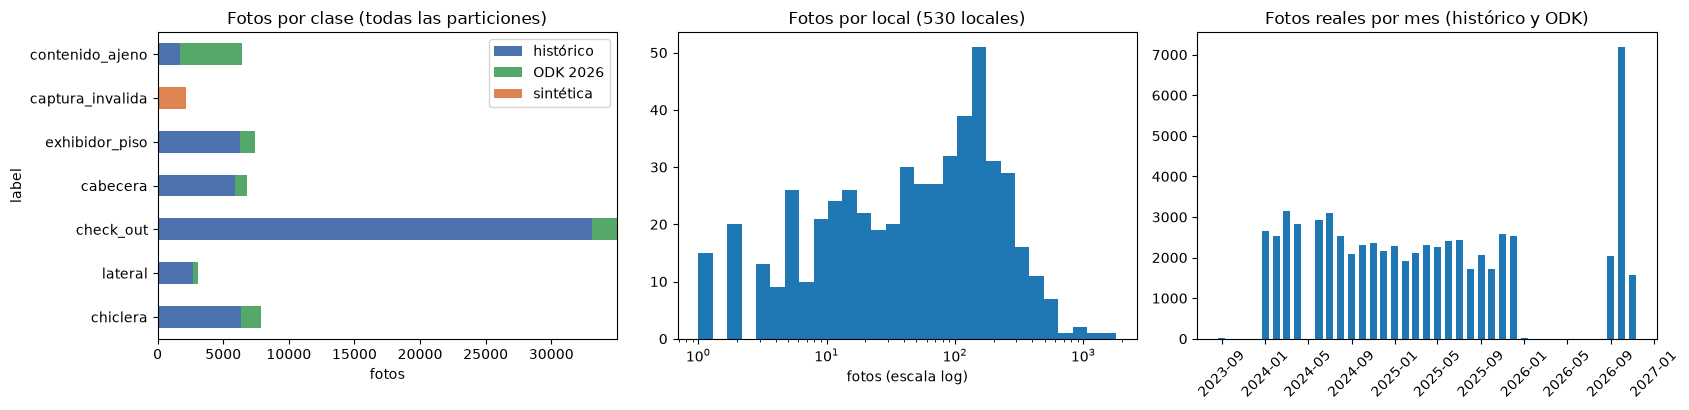

Desbalance: la clase mayor tiene 16.1 veces más fotos que la menor.
Mediana de fotos por local: 52 · el local más fotografiado: 1789


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
c = m.groupby(["label", "source"]).size().unstack(fill_value=0).reindex(CLASES)
FUENTE = {"hist": ("histórico", "#4C72B0"), "odk": ("ODK 2026", "#55A868"), "sint": ("sintética", "#DD8452")}
c.plot.barh(stacked=True, ax=ax[0], color=[FUENTE[s][1] for s in c]); ax[0].set_title("Fotos por clase (todas las particiones)")
ax[0].set_xlabel("fotos"); ax[0].legend([FUENTE[s][0] for s in c])
por_local = m[m.source == "hist"].groupby("store").size()
ax[1].hist(por_local, bins=np.logspace(0, np.log10(por_local.max()), 30)); ax[1].set_xscale("log")
ax[1].set_title(f"Fotos por local ({len(por_local)} locales)"); ax[1].set_xlabel("fotos (escala log)")
mes = m[m.source != "sint"].dropna(subset=["fecha"]).set_index("fecha").resample("MS").size()
ax[2].bar(mes.index, mes.values, width=20); ax[2].set_title("Fotos reales por mes (histórico y ODK)"); ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("Desbalance: la clase mayor tiene", round(c.sum(axis=1).max() / c.sum(axis=1).min(), 1), "veces más fotos que la menor.")
print("Mediana de fotos por local:", int(por_local.median()), "· el local más fotografiado:", int(por_local.max()))

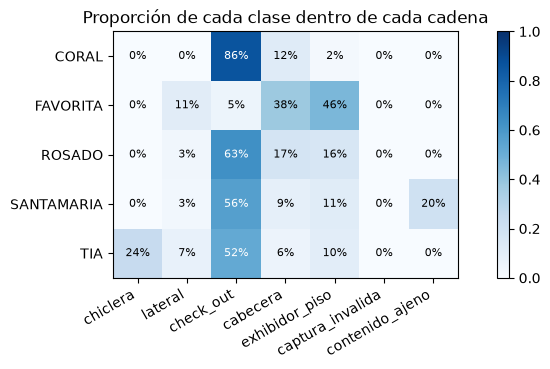

In [4]:
# Composición por cadena: si una cadena concentra un tipo de mueble, el modelo podría aprender la cadena.
tab = pd.crosstab(m[m.source == "hist"].cadena, m[m.source == "hist"].label, normalize="index").reindex(columns=CLASES).fillna(0)
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(tab.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASES)), CLASES, rotation=30, ha="right"); ax.set_yticks(range(len(tab)), tab.index)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        ax.text(j, i, f"{tab.values[i, j]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if tab.values[i, j] > .5 else "black")
ax.set_title("Proporción de cada clase dentro de cada cadena"); plt.colorbar(im, fraction=.02); plt.show()

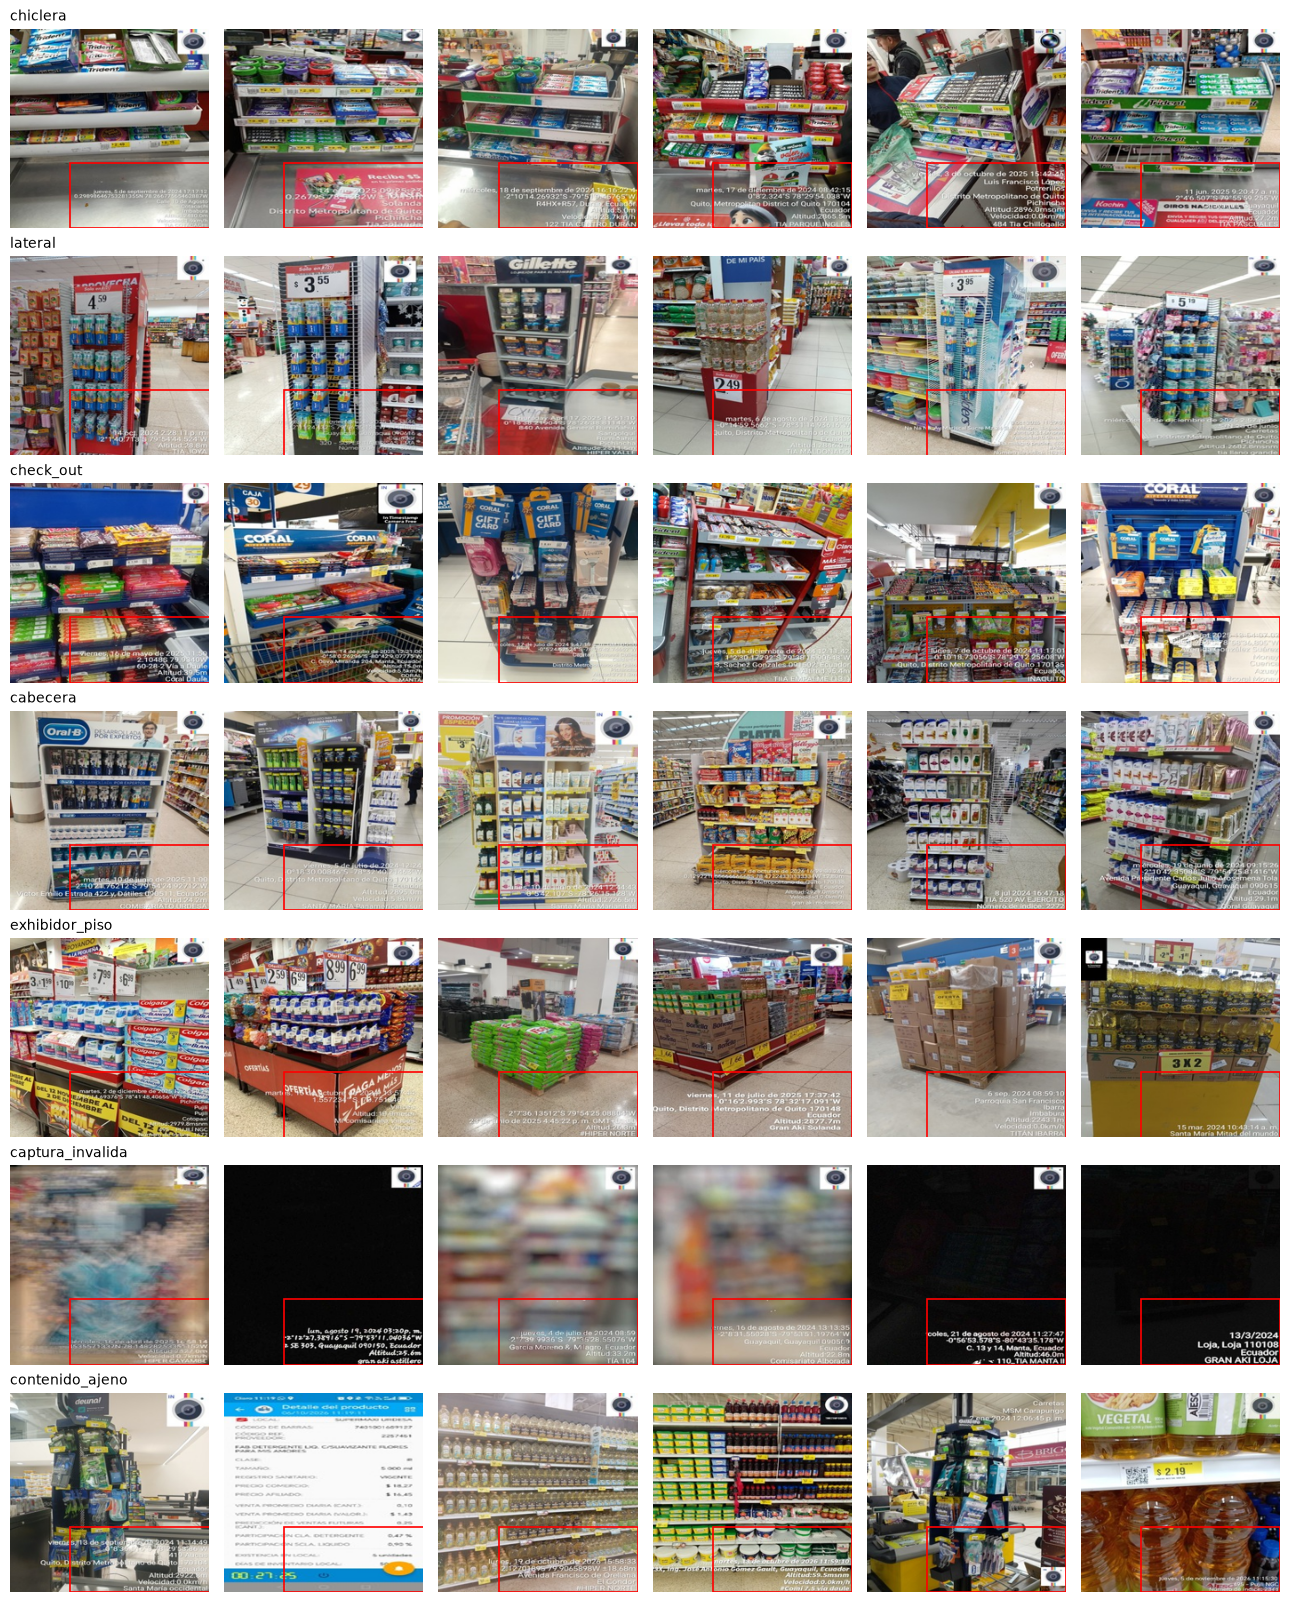

In [5]:
# Ejemplos por clase, tal como los ve el modelo (224x224) y con la máscara de la superposición en rojo.
from PIL import Image
fig, axs = plt.subplots(len(CLASES), 6, figsize=(13, 2.3 * len(CLASES)))
for i, c_ in enumerate(CLASES):
    s = m[m.label == c_].sample(6, random_state=SEED, replace=(m.label == c_).sum() < 6)
    for j, p in enumerate(s.path):
        a = axs[i, j]; a.imshow(Image.open(p).convert("RGB").resize((IMG, IMG))); a.axis("off")
        a.add_patch(plt.Rectangle((IMG * (1 - MASK_W), IMG * (1 - MASK_H)), IMG * MASK_W, IMG * MASK_H,
                                  fill=False, ec="red", lw=1.2))
        if j == 0: a.set_title(c_, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Hallazgos del EDA que condicionan el diseño**

- **Desbalance fuerte** (check out domina). Se usa **F1-macro** como métrica y pesos de clase balanceados: cada clase
  pesa igual, sin importar cuántas fotos tenga.
- **Pocos locales concentran muchas fotos** y cada local se visita cada mes. Toda validación se **agrupa por local**
  (`StratifiedGroupKFold`); de lo contrario el modelo reconocería el local, no el mueble.
- **La superposición de Timestamp Camera** (fecha, coordenadas y nombre del local, abajo a la derecha) delata el local
  y, vía el convenio, la clase. Se midió su tamaño en 777 fotos (p90: 0.70 de ancho × 0.33 de alto) y se
  **enmascara** con un rectángulo negro dentro del modelo.
- **Capturas inválidas reales casi no existen** en el histórico: la clase se completa con síntesis controlada.

## 4. Modelo: transfer learning

Cada técnica es una red convolucional **preentrenada en ImageNet** [3] y **congelada**, seguida de un clasificador
lineal. La red convierte cada imagen (224×224, con la máscara de la superposición) en el promedio de su último mapa de
activación: **MobileNetV3-Large** [4] da 960 valores por foto y **EfficientNet-B0** [5] da 1280. Son las dos
arquitecturas candidatas a correr en el teléfono. Sobre esa representación se entrena una **regresión logística
multinomial** regularizada.

Por qué la red va congelada: la validación cruzada repetida exige entrenar cientos de veces. Con la red fija, cada
ajuste toma segundos y la comparación mide la calidad de la representación de cada red, sin ruido de entrenamiento.
La salida de la red se calcula una vez y se guarda en Drive.

In [6]:
# Prompt (Claude Code): "empieza a entrenar con lo que tienes"; "¿estás probando los modelos propuestos en la tesis?"
import tensorflow as tf, keras

MASCARA = np.ones((IMG, IMG, 1), "float32")
MASCARA[-round(IMG * MASK_H):, -round(IMG * MASK_W):] = 0
REDES = {"mobilenetv3": keras.applications.MobileNetV3Large, "efficientnetb0": keras.applications.EfficientNetB0}

def cargar(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (IMG, IMG))            # float32 en [0, 255]: cada red trae su preprocesamiento

def representar(red, paths):
    cache = CACHE / f"{red}{'_rapido' if RAPIDO else ''}.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        if list(z["paths"]) == list(paths):
            return z["X"]
    base = REDES[red](include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3), pooling="avg")
    entrada = keras.Input((IMG, IMG, 3))
    congelada = keras.Model(entrada, base(entrada * MASCARA))
    ds = tf.data.Dataset.from_tensor_slices(list(paths)).map(cargar, num_parallel_calls=tf.data.AUTOTUNE)
    X = congelada.predict(ds.batch(256).prefetch(tf.data.AUTOTUNE), verbose=0).astype("float32")
    np.savez(cache, X=X, paths=np.array(list(paths), dtype=object))
    return X

todo = pd.concat([dev.path, test.path]).tolist()
X, t0 = {}, time.time()
for red in REDES:
    Z = representar(red, todo)
    X[red] = {"dev": Z[:len(dev)], "test": Z[len(dev):]}
    print(f"{red}: {Z.shape[1]} valores por foto · {time.time() - t0:.0f} s acumulados")
y_dev, y_test = dev.label.values, test.label.values
grupos = dev.store.values

mobilenetv3: 960 valores por foto · 0 s acumulados


efficientnetb0: 1280 valores por foto · 1 s acumulados


## 5. Pipelines

Cada técnica es un `Pipeline` de scikit-learn [6]: `StandardScaler` (media 0 y varianza 1 por valor) y regresión
logística multinomial con pesos de clase balanceados. Al ir en un pipeline, el escalado se ajusta **solo con los datos
de entrenamiento de cada fold**, sin fuga hacia el fold de validación.

No hay paso de selección de características: es un problema de imágenes resuelto con transfer learning, donde la red
ya entrega una representación compacta y aprendida; descartar dimensiones de ella no tiene un significado que lo
justifique.

La regularización es L2. scikit-learn minimiza ½‖θ‖² + C·Σᵢ pérdidaᵢ; dividiendo por C·m queda
**J(θ) = (1/m)·Σᵢ pérdidaᵢ + (λ/2m)·‖θ‖²** con **λ = 1/C**, la forma usual del curso. Ese λ es el hiperparámetro.

In [7]:
# Prompt (Claude Code): "estructura el proyecto con esta rúbrica en mente"; "no hace falta selección de características: es un problema de imágenes con transfer learning"
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_validate, learning_curve
from sklearn.metrics import log_loss, make_scorer
from sklearn.utils.class_weight import compute_sample_weight

def tecnica(lam=1.0):
    return Pipeline([("escala", StandardScaler()),
                     ("clf", LogisticRegression(C=1 / lam, class_weight="balanced", max_iter=5000))])

def kfold_repetido(y, grupos, repeticiones, folds):
    # k-fold repetido, estratificado por clase y agrupado por local: ningún local queda a la vez en entrenamiento
    # y validación dentro de un fold. Cada repetición usa otra semilla, es decir otra partición de locales.
    return [(tr, va) for r in range(repeticiones)
            for tr, va in StratifiedGroupKFold(folds, shuffle=True, random_state=SEED + r).split(np.zeros(len(y)), y, grupos)]

def perdida(y, p):
    # J: entropía cruzada con cada clase pesando igual, como en el entrenamiento (class_weight) y en el F1-macro.
    # Sin el término de regularización, como se mide el error de entrenamiento y de validación.
    return log_loss(y, p, sample_weight=compute_sample_weight("balanced", y), labels=sorted(CLASES))

J = make_scorer(perdida, greater_is_better=False, response_method="predict_proba")
f1_cv = lambda pipe, Xd, folds: cross_val_score(pipe, Xd, y_dev, cv=folds, scoring="f1_macro", n_jobs=-1)
tecnica()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escala', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecate

## 6. Optimización de hiperparámetros

### 6.1 λ: sesgo y varianza

**Optuna** [13] busca el λ que minimiza **J_val**, medido con un **k-fold repetido 5×2 agrupado por local** sobre el
conjunto de desarrollo. Cada intento registra también **J_entr**, así los intentos dibujan la curva de sesgo y varianza
[7]. Los primeros intentos son una grilla de λ entre 0.001 y 1000, para que la curva cubra los dos extremos; después
el muestreador TPE de Optuna se concentra alrededor del mínimo:

- **λ chico** (poca regularización): J_entr bajo y J_val alto. El modelo memoriza el entrenamiento: **alta varianza**.
- **λ grande** (mucha regularización): J_entr y J_val altos y parecidos. El modelo es demasiado simple: **alto sesgo**.
- **λ\*** es el que minimiza J_val: el mejor equilibrio entre ambos.

Cada red se optimiza por separado y con los mismos folds, para compararlas luego en igualdad de condiciones.

In [8]:
# Prompt (Claude Code): "para la optimización de hiperparámetros, la optimización de sesgo/varianza para lambda, y determinar el tamaño de entrenamiento m en que la curva de aprendizaje se estabiliza"
folds_hpo = kfold_repetido(y_dev, grupos, HPO["repeticiones"], HPO["folds"])
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
estudios, curva_lam, lam_opt = {}, {}, {}
for red in REDES:
    def objetivo(trial, Xd=X[red]["dev"]):
        lam = trial.suggest_float("lambda", 1e-3, 1e3, log=True)
        r = cross_validate(tecnica(lam), Xd, y_dev, cv=folds_hpo, n_jobs=-1, return_train_score=True,
                           scoring={"J": J, "f1": "f1_macro"})
        trial.set_user_attr("J_entr", -r["train_J"].mean()); trial.set_user_attr("J_entr_sd", r["train_J"].std())
        trial.set_user_attr("J_val_sd", r["test_J"].std()); trial.set_user_attr("F1_val", r["test_f1"].mean())
        return -r["test_J"].mean()                     # J_val: lo que se minimiza
    t0 = time.time()
    e = estudios[red] = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    for lam in LAMBDAS:
        e.enqueue_trial({"lambda": float(lam)})
    e.optimize(objetivo, n_trials=HPO["intentos"])
    curva_lam[red] = pd.DataFrame([{"lambda": tr.params["lambda"], "J_val": tr.value, **tr.user_attrs}
                                   for tr in e.trials]).sort_values("lambda").reset_index(drop=True)
    lam_opt[red] = e.best_params["lambda"]
    print(f"{red}: λ* = {lam_opt[red]:.3g} · J_val = {e.best_value:.4f} · F1-macro val = "
          f"{e.best_trial.user_attrs['F1_val']:.4f} ({len(e.trials)} intentos, {time.time() - t0:.0f} s)")
curva_lam[next(iter(REDES))].round(4)

mobilenetv3: λ* = 209 · J_val = 0.2255 · F1-macro val = 0.9164 (30 intentos, 1099 s)


efficientnetb0: λ* = 262 · J_val = 0.1988 · F1-macro val = 0.9292 (30 intentos, 1615 s)


,lambda,J_val,J_entr,J_entr_sd,J_val_sd,F1_val
0,0.0010,1.6480,0.0046,0.0008,0.1097,0.8745
1,0.0100,1.5487,0.0067,0.0008,0.0886,0.8751
2,0.1000,1.2368,0.0151,0.0016,0.0546,0.8779
3,0.1767,1.1151,0.0187,0.0019,0.0466,0.8789
4,0.7147,0.7908,0.0294,0.0017,0.0360,0.8858
5,1.0000,0.7123,0.0324,0.0018,0.0333,0.8875
6,3.2893,0.4915,0.0440,0.0016,0.0290,0.8938
7,4.4201,0.4475,0.0473,0.0014,0.0246,0.8954
8,8.0981,0.3750,0.0545,0.0013,0.0207,0.8999
9,10.0000,0.3533,0.0574,0.0012,0.0187,0.9014


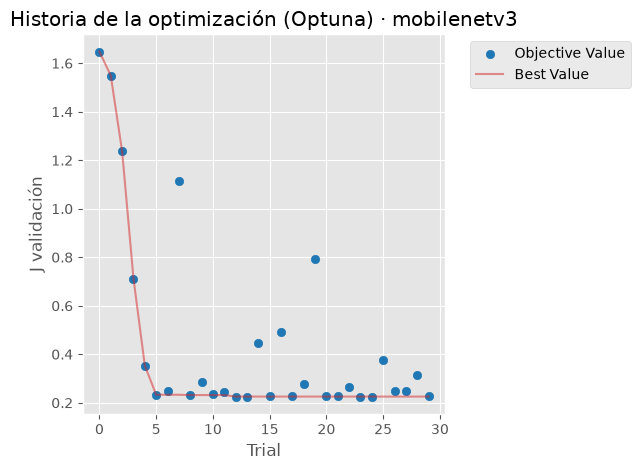

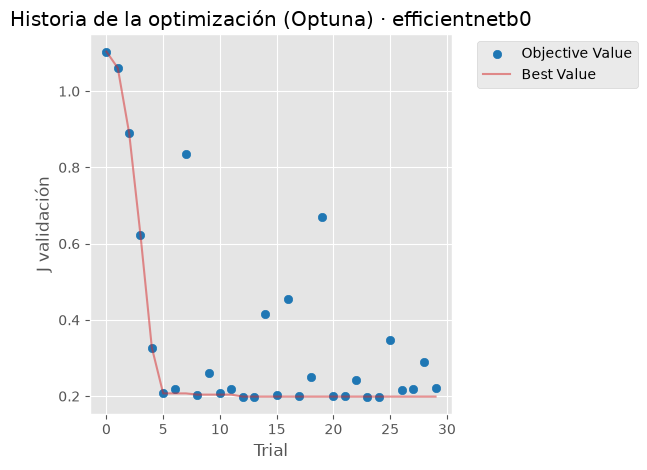

In [9]:
from optuna.visualization.matplotlib import plot_optimization_history
for red, e in estudios.items():
    plot_optimization_history(e); plt.title(f"Historia de la optimización (Optuna) · {red}"); plt.ylabel("J validación"); plt.show()

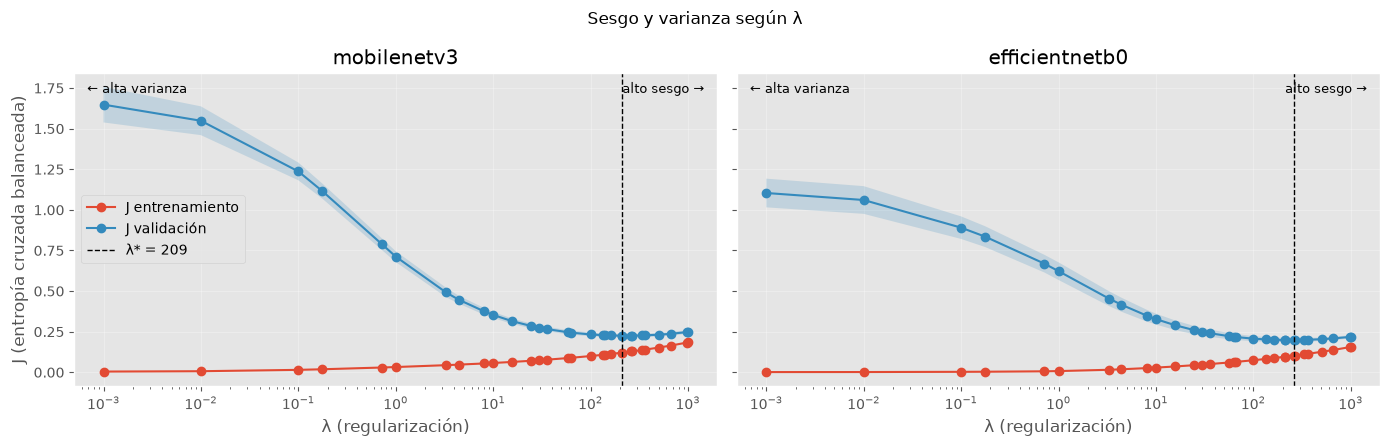

In [10]:
fig, axs = plt.subplots(1, len(REDES), figsize=(14, 4.5), sharey=True)
for a, red in zip(axs, REDES):
    c = curva_lam[red]
    for col, lab in (("J_entr", "J entrenamiento"), ("J_val", "J validación")):
        a.plot(c["lambda"], c[col], "o-", label=lab)
        a.fill_between(c["lambda"], c[col] - c[col + "_sd"], c[col] + c[col + "_sd"], alpha=.2)
    a.axvline(lam_opt[red], color="k", ls="--", lw=1, label=f"λ* = {lam_opt[red]:.3g}")
    a.set_xscale("log"); a.set_xlabel("λ (regularización)"); a.set_title(red); a.grid(alpha=.3)
    a.text(.02, .97, "← alta varianza", transform=a.transAxes, va="top", fontsize=9)
    a.text(.98, .97, "alto sesgo →", transform=a.transAxes, va="top", ha="right", fontsize=9)
axs[0].set_ylabel("J (entropía cruzada balanceada)"); axs[0].legend(loc="center left")
plt.suptitle("Sesgo y varianza según λ"); plt.tight_layout(); plt.show()

**Lectura.** La curva tiene la forma esperada. Con λ = 10⁻³ el modelo casi memoriza el entrenamiento (J_entr < 0.01)
pero J_val es 1.65 en MobileNetV3 y ≈ 1.1 en EfficientNet-B0: **alta varianza**. Al subir λ, J_val baja hasta un
mínimo en **λ\* = 209** (MobileNetV3) y **λ\* = 262** (EfficientNet-B0); después J_entr y J_val suben juntos: **alto
sesgo**. El mínimo cae dentro del rango explorado, no en un borde, y Optuna concentró sus intentos a su alrededor
(historial de arriba).

La regularización óptima es fuerte: sin ella J_val se multiplica por 5 a 7. Además, el F1-macro de validación cambia
poco en todo el rango (0.875 → 0.917 en MobileNetV3) mientras J cae a la séptima parte: con λ chico el modelo acierta
casi lo mismo, pero cuando se equivoca lo hace con probabilidades exageradas, y la entropía cruzada lo castiga.

### 6.2 Tamaño de entrenamiento m: curva de aprendizaje

Con λ\* fijo se mide **J_entr(m)** y **J_val(m)** entrenando con una fracción creciente *m* del entrenamiento de cada
fold. J_val baja al crecer *m* hasta que se **estabiliza**: desde ahí, más fotos ya no mejoran el modelo.

Criterio para **m\***: el menor *m* tal que lo que J_val todavía mejora hasta el *m* máximo es menor que la desviación
estándar de J_val entre folds. Es decir, la mejora restante ya no se distingue del ruido de la validación.

Si al final J_val y J_entr quedan cerca, el modelo está en régimen de **sesgo**: más datos no ayudan y para mejorar hace
falta un modelo más flexible (por ejemplo, ajustar la red, sección 10). Si quedan lejos, está en régimen de
**varianza** y más datos o más regularización sí ayudarían.

mobilenetv3: m* = 28,126 fotos de 37,962 · J_val(m*) = 0.2337 · J_val(m máx) = 0.2255 · brecha final J_val - J_entr = 0.1047


efficientnetb0: m* = 28,126 fotos de 37,962 · J_val(m*) = 0.2074 · J_val(m máx) = 0.1988 · brecha final J_val - J_entr = 0.0961


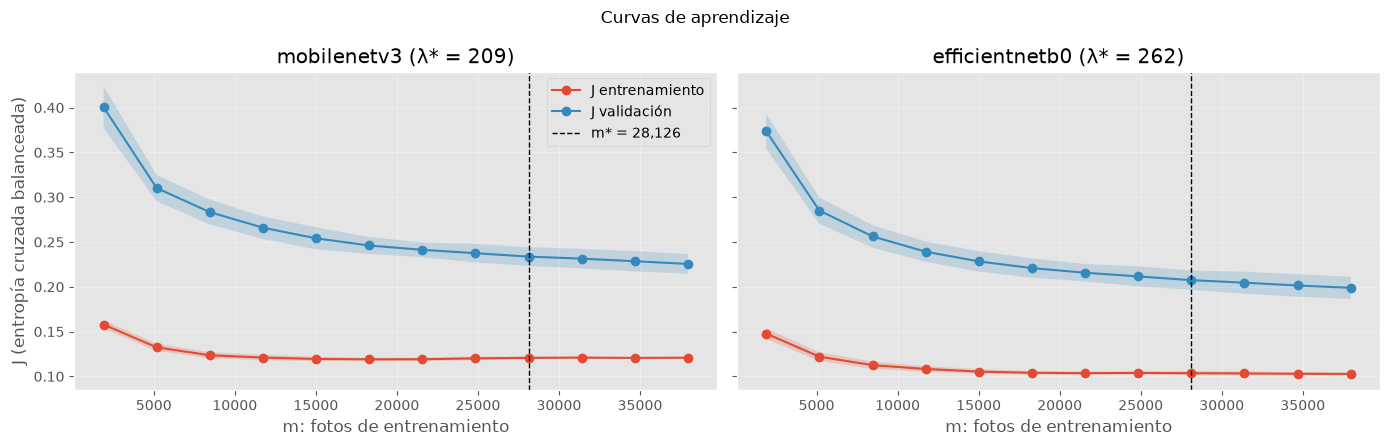

In [11]:
curva_m, m_opt = {}, {}
for red in REDES:
    n, tr, va = learning_curve(tecnica(lam_opt[red]), X[red]["dev"], y_dev, cv=folds_hpo, train_sizes=TAMANOS,
                               scoring=J, n_jobs=-1, shuffle=True, random_state=SEED)
    tr, va = -tr, -va
    curva_m[red] = (n, tr, va)
    restante = va.mean(1) - va.mean(1)[-1]
    m_opt[red] = int(n[np.argmax(restante <= va.std(1)[-1])])
    brecha = va.mean(1)[-1] - tr.mean(1)[-1]
    print(f"{red}: m* = {m_opt[red]:,} fotos de {n[-1]:,} · J_val(m*) = {va.mean(1)[n == m_opt[red]][0]:.4f}"
          f" · J_val(m máx) = {va.mean(1)[-1]:.4f} · brecha final J_val - J_entr = {brecha:.4f}")

fig, axs = plt.subplots(1, len(REDES), figsize=(14, 4.5), sharey=True)
for a, red in zip(axs, REDES):
    n, tr, va = curva_m[red]
    for s, lab in ((tr, "J entrenamiento"), (va, "J validación")):
        a.plot(n, s.mean(1), "o-", label=lab); a.fill_between(n, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=.2)
    a.axvline(m_opt[red], color="k", ls="--", lw=1, label=f"m* = {m_opt[red]:,}")
    a.set_title(f"{red} (λ* = {lam_opt[red]:.3g})"); a.set_xlabel("m: fotos de entrenamiento"); a.grid(alpha=.3)
axs[0].set_ylabel("J (entropía cruzada balanceada)"); axs[0].legend()
plt.suptitle("Curvas de aprendizaje"); plt.tight_layout(); plt.show()

**Lectura.** En las dos redes **m\* = 28 126 fotos**, tres cuartos del entrenamiento de cada fold (37 962). Desde ahí
J_val baja apenas 0.008 más (MobileNetV3: 0.234 → 0.226; EfficientNet-B0: 0.207 → 0.199), menos que su desviación
entre folds (≈ 0.011): la curva todavía desciende un poco al final, pero dentro del ruido de la validación. J_entr está
plano desde unas 12 000 fotos (≈ 0.12 y ≈ 0.10).

La brecha final J_val − J_entr (≈ 0.10) no es ruido (unas nueve veces la desviación entre folds), y tampoco se cierra
al agregar fotos. No es varianza clásica: la validación es de **locales nuevos**, cada uno con su iluminación, sus
muebles y sus ángulos, y más fotos de los mismos 452 locales no enseñan eso. Lo que puede mejorar el modelo es más
**diversidad** (locales nuevos) o un modelo **más flexible** (ajuste fino, sección 10), no más volumen.

## 7. Comparación estadística: MobileNetV3 vs EfficientNet-B0

Las dos técnicas son el mismo pipeline, con el λ* de cada red, sobre la representación de cada red. Se evalúan con un **k-fold repetido
10×10 agrupado por local**, con **los mismos folds** para ambas, así cada fold produce un par de puntajes (F1-macro).

- **H0:** las dos técnicas tienen el mismo F1-macro esperado. **H1:** difieren. Nivel α = 0.05.
- **Wilcoxon de rangos con signo** [8] sobre las 100 diferencias pareadas: no supone normalidad.
- **t-test corregido de Nadeau y Bengio** [9]: en el k-fold repetido los conjuntos de entrenamiento se solapan, las
  diferencias no son independientes y el t-test ingenuo subestima la varianza (demasiados falsos positivos). La
  corrección infla la varianza por el factor (1/n + n_val/n_entr).

100 folds pareados (992 s)
F1-macro mobilenetv3: 0.9178 ± 0.0084 · efficientnetb0: 0.9307 ± 0.0083
diferencia media (mobilenetv3 - efficientnetb0): -0.0129 · mobilenetv3 gana en 4% de los folds
Wilcoxon: estadístico 23.0, p = 7.79e-18
t-test corregido (Nadeau-Bengio): t = -5.565, p = 2.24e-07
=> se rechaza H0


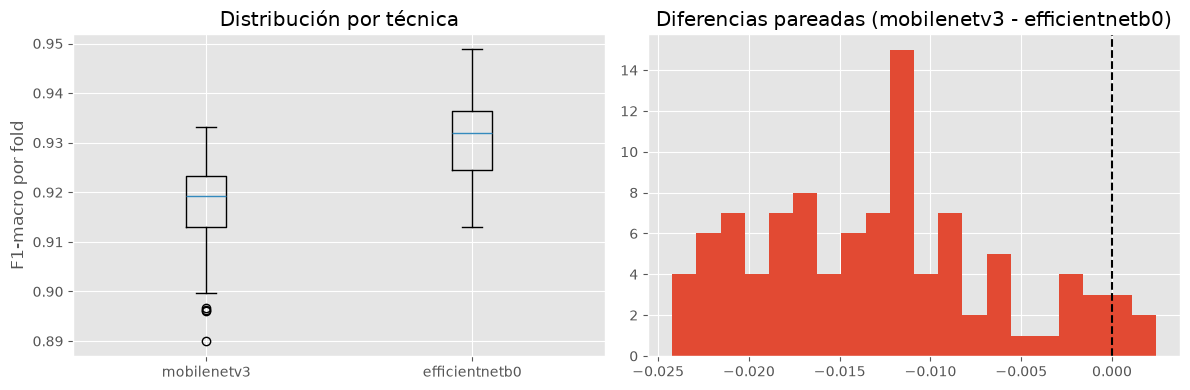

In [12]:
# Prompt (Claude Code): comparación estadística elegida por el autor: "MobileNetV3 vs EfficientNet"
from scipy import stats
folds_cmp = kfold_repetido(y_dev, grupos, COMP["repeticiones"], COMP["folds"])
t0 = time.time()
puntajes = {red: f1_cv(tecnica(lam_opt[red]), X[red]["dev"], folds_cmp) for red in REDES}
a_, b_ = (puntajes[r] for r in REDES)
d = a_ - b_
w = stats.wilcoxon(a_, b_)
n_va = np.mean([len(v) for _, v in folds_cmp]); n_tr = np.mean([len(t) for t, _ in folds_cmp])
t_c = d.mean() / np.sqrt((1 / len(d) + n_va / n_tr) * d.var(ddof=1))
p_c = 2 * stats.t.sf(abs(t_c), len(d) - 1)
r1, r2 = REDES
print(f"{len(d)} folds pareados ({time.time() - t0:.0f} s)")
print(f"F1-macro {r1}: {a_.mean():.4f} ± {a_.std(ddof=1):.4f} · {r2}: {b_.mean():.4f} ± {b_.std(ddof=1):.4f}")
print(f"diferencia media ({r1} - {r2}): {d.mean():+.4f} · {r1} gana en {(d > 0).mean():.0%} de los folds")
print(f"Wilcoxon: estadístico {w.statistic:.1f}, p = {w.pvalue:.2e}")
print(f"t-test corregido (Nadeau-Bengio): t = {t_c:.3f}, p = {p_c:.2e}")
print("=> se rechaza H0" if max(w.pvalue, p_c) < .05 else "=> no se rechaza H0: la diferencia no es significativa")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot([a_, b_], tick_labels=list(REDES)); ax[0].set_ylabel("F1-macro por fold"); ax[0].set_title("Distribución por técnica")
ax[1].hist(d, bins=20); ax[1].axvline(0, color="k", ls="--"); ax[1].set_title(f"Diferencias pareadas ({r1} - {r2})")
plt.tight_layout(); plt.show()

**Lectura.** EfficientNet-B0 supera a MobileNetV3 por **1.3 puntos de F1-macro** (0.931 vs 0.918); MobileNetV3 gana
solo en 4 de los 100 folds. Ambas pruebas rechazan H0: Wilcoxon p = 7.8·10⁻¹⁸ y t corregido p = 2.2·10⁻⁷. La distancia
entre los dos p es la corrección de Nadeau-Bengio en acción: el Wilcoxon trata los 100 folds como independientes y no
lo son. Aun con la corrección, la diferencia es significativa, y es mayor que la variación entre folds (± 0.008): con
la red congelada, EfficientNet-B0 es mejor en casi cualquier partición de los locales.

## 8. Visualización del espacio de características con t-SNE

t-SNE [10] proyecta los rasgos a 2 dimensiones conservando vecindades locales. Se usa una submuestra estratificada
del conjunto de desarrollo, reducida antes a 50 componentes con PCA (práctica estándar para estabilizar t-SNE), con
el **color según la clase**. Grupos compactos y separados indican que la representación ya distingue los muebles
antes de cualquier clasificador. Las distancias entre grupos lejanos no tienen interpretación en t-SNE.

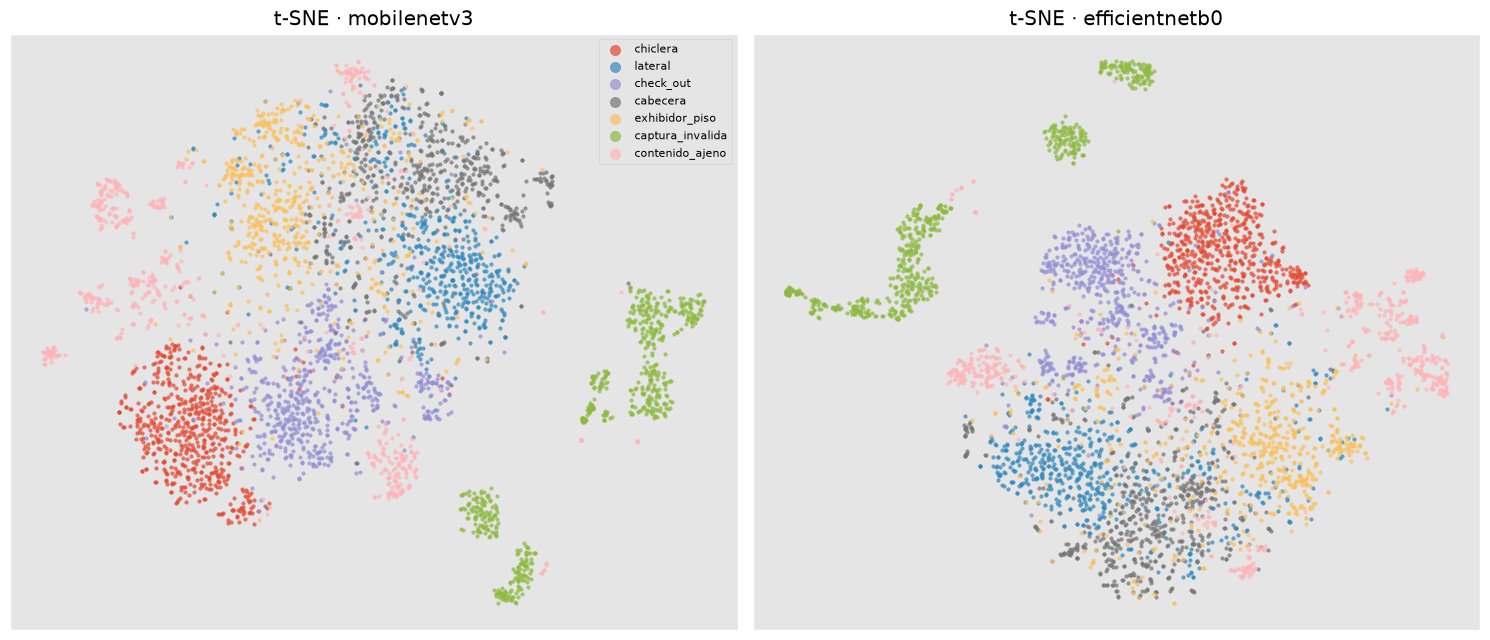

In [13]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
idx = dev.groupby("label").sample(n=min(600, dev.label.value_counts().min()), random_state=SEED).index
fig, axs = plt.subplots(1, len(REDES), figsize=(15, 6.5))
for a, red in zip(axs, REDES):
    Z = StandardScaler().fit_transform(X[red]["dev"][idx])
    E = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(PCA(50, random_state=SEED).fit_transform(Z))
    for c_ in CLASES:
        s = y_dev[idx] == c_
        a.scatter(E[s, 0], E[s, 1], s=6, alpha=.7, label=c_)
    a.set_title(f"t-SNE · {red}"); a.set_xticks([]); a.set_yticks([])
axs[0].legend(markerscale=3, fontsize=8, loc="best"); plt.tight_layout(); plt.show()

**Lectura.** En las dos redes las **capturas inválidas** forman grupos aparte: casi todas son sintéticas, y
probablemente cada tipo de degradación forma su propio grupo. **Chiclera** queda compacta. **Contenido ajeno** se
reparte en varios grupos pequeños en los bordes: es una clase heterogénea (percha, producto suelto, personas,
pantallas). **Lateral, cabecera y exhibidor de piso** se mezclan en el centro: son muebles grandes, junto a la percha y
con producto parecido. Es la misma confusión que muestra la prueba (sección 9).

## 9. Evaluación en el conjunto de prueba

Cada técnica se reentrena con todo el conjunto de desarrollo y se evalúa **una sola vez** en la prueba: los locales
que nunca se vieron, solo fotos reales revisadas a mano, del histórico y de ODK. Limitación conocida: la prueba tiene **solo dos** capturas
inválidas reales, así que su recall no es una medida (se reporta F1 también sobre las clases presentes).


===== mobilenetv3 =====  F1-macro (7 clases) 0.7650 · (clases con ≥10 fotos en prueba) 0.8925
                  precision    recall  f1-score   support

        chiclera      0.967     0.984     0.975      1551
         lateral      0.756     0.819     0.786       624
       check_out      0.991     0.962     0.976      6943
        cabecera      0.911     0.919     0.915      1327
  exhibidor_piso      0.874     0.866     0.870      1440
captura_invalida      0.000     0.000     0.000         2
 contenido_ajeno      0.741     0.950     0.832       437

        accuracy                          0.941     12324
       macro avg      0.748     0.786     0.765     12324
    weighted avg      0.944     0.941     0.942     12324



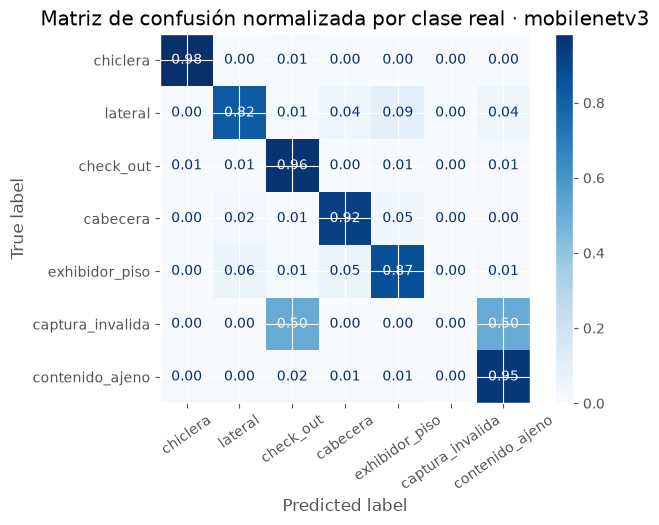


===== efficientnetb0 =====  F1-macro (7 clases) 0.8369 · (clases con ≥10 fotos en prueba) 0.9097
                  precision    recall  f1-score   support

        chiclera      0.976     0.981     0.979      1551
         lateral      0.783     0.833     0.807       624
       check_out      0.992     0.973     0.983      6943
        cabecera      0.909     0.931     0.920      1327
  exhibidor_piso      0.894     0.875     0.885      1440
captura_invalida      0.333     0.500     0.400         2
 contenido_ajeno      0.815     0.968     0.885       437

        accuracy                          0.951     12324
       macro avg      0.815     0.866     0.837     12324
    weighted avg      0.953     0.951     0.952     12324



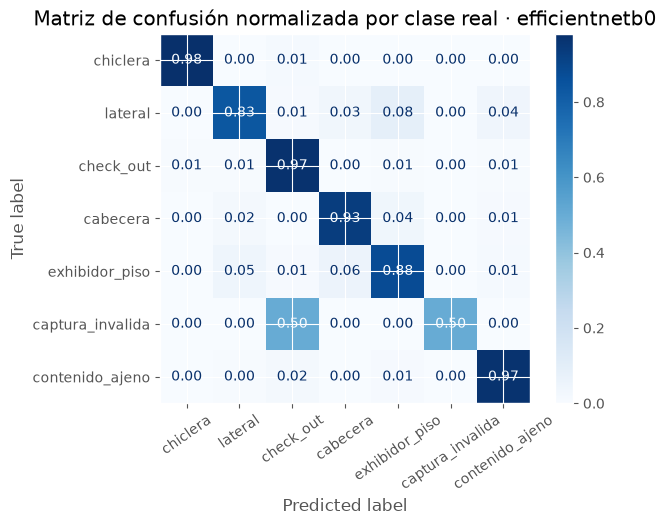

,f1_macro_7,f1_macro_presentes
mobilenetv3,0.7650,0.8925
efficientnetb0,0.8369,0.9097


In [14]:
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
finales = {}
for red in REDES:
    pipe = tecnica(lam_opt[red]).fit(X[red]["dev"], y_dev)
    pred = pipe.predict(X[red]["test"])
    presentes = [c_ for c_ in CLASES if (y_test == c_).sum() >= 10]
    finales[red] = {"f1_macro_7": f1_score(y_test, pred, labels=CLASES, average="macro", zero_division=0),
                    "f1_macro_presentes": f1_score(y_test, pred, labels=presentes, average="macro", zero_division=0)}
    print(f"\n===== {red} =====  F1-macro (7 clases) {finales[red]['f1_macro_7']:.4f} · "
          f"(clases con ≥10 fotos en prueba) {finales[red]['f1_macro_presentes']:.4f}")
    print(classification_report(y_test, pred, labels=CLASES, zero_division=0, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CLASES, normalize="true", values_format=".2f",
                                            xticks_rotation=35, cmap="Blues")
    plt.title(f"Matriz de confusión normalizada por clase real · {red}"); plt.show()
pd.DataFrame(finales).T.round(4)

**Lectura.** En 108 locales nunca vistos, EfficientNet-B0 logra **F1-macro 0.910** sobre las 6 clases con al menos 10
fotos (exactitud 0.951) y MobileNetV3 0.892 (exactitud 0.941). El orden coincide con la validación cruzada, pero el
nivel queda unos 2 puntos abajo (0.931 y 0.918): la validación cruzada incluye las capturas sintéticas y las fotos de
SOS y Promociones, probablemente más fáciles que las reales, mientras la prueba usa solo fotos revisadas a mano.

- **Lateral es la clase más difícil** (F1 0.81 y 0.79): se confunde con exhibidor de piso (8–9 %), contenido ajeno
  (4 %) y cabecera (3–4 %).
- **Contenido ajeno** se detecta casi siempre (recall 0.97 y 0.95), con precisión 0.82 y 0.74: el modelo marca como
  contenido ajeno algunas fotos de muebles, que para el mercaderista serían alertas falsas. Los pesos balanceados
  empujan hacia esta clase.
- **Captura inválida no se puede evaluar**: hay dos reales en la prueba. EfficientNet-B0 acierta una y marca otras dos
  fotos como inválidas por error; MobileNetV3 no acierta ninguna. Eso es lo que baja el F1 de 7 clases a 0.84 y 0.77;
  no es un error de fondo.

### 9.1 Campo 2026: fotos de ODK y verificación contra lo declarado

La prueba incluye las fotos de ODK de los locales de prueba: septiembre a noviembre de 2026, nueve meses después de la
foto histórica más reciente y con los convenios vigentes. El F1-macro se reporta por separado para cada fuente.

Cada foto de ODK trae además el **mueble declarado**, lo que permite la verificación de la sección 5.9 con sumisiones
reales. El sistema predice entre los muebles con convenio del local (los declarados en ODK para ese local) y las dos
categorías de rechazo, y **alerta si la predicción no es el mueble declarado**:

- **Falsas alarmas**: alertas sobre fotos que sí muestran lo declarado. Molestan al mercaderista sin motivo.
- **Errores detectados**: alertas sobre fotos que no lo muestran (otro mueble, la percha, una foto inservible). Es lo
  que el sistema debe atrapar en el local.

In [15]:
# Prompt (Claude Code): "¿cómo usaríamos las fotos de ODK en la realidad?" -> campo 2026 y verificación (sección 5.9).
from tesis.metrics import IDX, conditional_pred
MUEBLES = CLASES[:5]
odk_t = (test.source == "odk").values
v = odk_t & test.declarado.isin(MUEBLES).values               # fotos de ODK declaradas como uno de los 5 muebles
ok = (y_test[v] == test.declarado.values[v])                   # la foto muestra lo declarado
contratos = m[(m.source == "odk") & m.declarado.isin(MUEBLES)].groupby("store").declarado.agg(set).to_dict()
print(f"ODK en prueba: {odk_t.sum():,} fotos de {test.store[odk_t].nunique()} locales · verificables: {v.sum():,}"
      f" · muestran lo declarado: {ok.sum():,} · errores reales de campo: {(~ok).sum()}")
print(pd.crosstab(test.declarado.values[v][~ok], y_test[v][~ok], rownames=["declarado"], colnames=["la foto muestra"]))
filas = []
for red in REDES:
    pipe = tecnica(lam_opt[red]).fit(X[red]["dev"], y_dev)
    P = pd.DataFrame(pipe.predict_proba(X[red]["test"]), columns=pipe.classes_)[CLASES].to_numpy()
    pred = np.array(CLASES)[P.argmax(1)]
    fila = {"red": red}
    for nombre, s in (("histórico", ~odk_t), ("ODK 2026", odk_t)):
        pres = [c_ for c_ in CLASES if (y_test[s] == c_).sum() >= 10]
        fila[f"F1-macro {nombre}"] = f1_score(y_test[s], pred[s], labels=pres, average="macro", zero_division=0)
    alerta = conditional_pred(P[v], test.store.values[v], contratos) != test.declarado[v].map(IDX).values
    fila |= {"falsas alarmas": alerta[ok].mean(), "errores detectados": alerta[~ok].mean()}
    filas.append(fila)
pd.DataFrame(filas).set_index("red").round(3)

ODK en prueba: 1,164 fotos de 57 locales · verificables: 1,079 · muestran lo declarado: 984 · errores reales de campo: 95
la foto muestra  cabecera  captura_invalida  check_out  chiclera  \
declarado                                                          
cabecera                0                 0          0         0   
check_out               0                 1          0         5   
chiclera                0                 0         13         0   
exhibidor_piso         18                 0          0         0   
lateral                 5                 0          0         0   

la foto muestra  contenido_ajeno  exhibidor_piso  lateral  
declarado                                                  
cabecera                       6              13       12  
check_out                      0               0        0  
chiclera                       0               0        0  
exhibidor_piso                 1               0       17  
lateral                        4         

,F1-macro histórico,F1-macro ODK 2026,falsas alarmas,errores detectados
red,,,,
mobilenetv3,0.889,0.911,0.051,0.716
efficientnetb0,0.908,0.919,0.047,0.768


**Lectura.** De las 1 079 fotos de ODK verificables en la prueba (57 locales), 984 muestran el mueble declarado y 95
no (9 %). Casi todos esos errores de campo son **otro mueble** del local (83 de 95), no la percha (11) ni una foto
inservible (1): un exhibidor de piso declarado que en la foto es una cabecera o un lateral, una cabecera que es un
exhibidor o un lateral, una chiclera que es un check out. Son justo los muebles que el modelo confunde entre sí.

- **El modelo no se degrada en 2026**: el F1-macro en las fotos de ODK (0.919 y 0.911) es igual o mayor que en las
  fotos históricas de los mismos locales de prueba (0.908 y 0.889). Ayuda que el desarrollo incluye fotos de ODK de
  otros locales.
- **Como verificador**, EfficientNet-B0 alerta en el 4.7 % de las fotos correctas y atrapa el 77 % de los errores
  (MobileNetV3: 5.1 % y 72 %). Con 9 % de errores, unas 6 de cada 10 alertas son errores de verdad. Una falsa alarma
  cuesta repetir la foto; un error no detectado es un mueble pagado sin evidencia.

## 10. Extensión: ajuste fino y despliegue en el teléfono

Las técnicas anteriores congelan la red. Para la tesis, además, se **ajustaron de punta a punta** las tres
arquitecturas del protocolo (ResNet-50 como referencia, MobileNetV3-Large y EfficientNet-B0), en dos experimentos (A:
locales nunca vistos; B: el último trimestre de 2025) y un control sin máscara, y se **cuantizaron a int8** para el
teléfono (`notebooks/entrenar_tesis.ipynb`). Si esos resultados están en Drive, se resumen aquí.

In [16]:
import glob
runs = DRIVE / "runs_odk" if (DRIVE / "runs_odk").exists() else DRIVE / "runs"  # runs_odk: reentrenados con ODK
filas = []
for f in sorted(glob.glob(str(runs / "*" / "metrics_*.json"))):
    mm = json.load(open(f))
    pc = [v for v in mm["per_class"].values() if v["support"] > 0]
    f1p = [2 * v["precision"] * v["recall"] / ((v["precision"] + v["recall"]) or 1) for v in pc]
    filas.append({"run": Path(f).parent.name, "formato": Path(f).stem.replace("metrics_", ""),
                  "f1_macro": mm["f1_macro"], "f1_presentes": np.mean(f1p), "MB": mm["size_mb"]})
if not filas:  # sin la carpeta de Drive: la tabla de la última corrida de notebooks/entrenar_tesis.ipynb
    print("Sin", runs, "· tabla de notebooks/ajuste_fino.csv")
pd.DataFrame(filas).round(3) if filas else pd.read_csv("notebooks/ajuste_fino.csv")

Sin data\proyecto_ml\runs · tabla de notebooks/ajuste_fino.csv


,run,formato,f1_macro,f1_presentes,MB
0,A_efficientnetb0,model,0.927,0.927,16.620
1,A_efficientnetb0,model_int8,0.768,0.768,4.761
2,A_mobilenetv3,model,0.919,0.919,12.444
3,A_mobilenetv3,model_int8,0.840,0.840,3.404
4,A_mobilenetv3_nomask,model,0.969,0.969,12.108
5,A_mobilenetv3_nomask,model_int8,0.807,0.807,3.356
6,A_resnet50,model,0.926,0.926,90.996
7,A_resnet50,model_int8,0.925,0.925,23.212
8,B_efficientnetb0,model,0.683,0.957,16.620
9,B_efficientnetb0,model_int8,0.466,0.653,4.761


Lo que mostraron esos experimentos (F1-macro en prueba; A: locales nunca vistos, B: el último trimestre de 2025). Son
corridas anteriores a las fotos de ODK; `entrenar_tesis.ipynb` (v3) las repite con ODK en `runs_odk/`:

- **El ajuste fino mejora a las redes congeladas, pero poco**: en el experimento A, MobileNetV3 0.919 (congelada:
  0.892) y EfficientNet-B0 0.927 (congelada: 0.910). Es coherente con la curva de aprendizaje: el límite está en la
  diversidad de los datos más que en la flexibilidad del modelo. Son corridas distintas y su prueba no es idéntica,
  así que la comparación es orientativa.
- **El modelo no se degrada en el tiempo**: en el experimento B, sobre las clases presentes, las tres redes logran
  0.95 a 0.96. El F1-macro de 7 clases (≈ 0.68) cae porque dos clases no aparecen en ese trimestre.
- **La cuantización int8 completa rompe las arquitecturas móviles**: en A, MobileNetV3 cae a 0.840 y EfficientNet-B0
  a 0.768, mientras ResNet-50 no pierde nada (0.925) pero pesa 23 MB, sobre el límite de 20 MB. Las activaciones
  *swish*/*hard-swish* y los bloques de atención (SE) toleran mal la cuantización entera.
- **Sin la máscara, MobileNetV3 sube a 0.969.** Puede ser un atajo (leer cadena y ciudad en el texto) o que la
  máscara tapa parte del mueble; distinguirlo requiere un diagnóstico propio (pendiente).

## 11. Conclusiones

1. **La mejor técnica es EfficientNet-B0 congelada con regresión logística (λ\* ≈ 260)**: F1-macro 0.931 en
   validación cruzada 10×10 y 0.910 en prueba, contra 0.918 y 0.892 de MobileNetV3. La diferencia es estadísticamente
   significativa (Wilcoxon y t corregido) y consistente: MobileNetV3 gana solo en 4 de 100 folds.
2. **La regularización fuerte es necesaria**: en λ\* ≈ 200–260 el modelo está en el equilibrio entre sesgo y
   varianza; sin regularizar, J_val se multiplica por 5 a 7.
3. **Más fotos de los mismos locales ya casi no ayudan**: la curva de aprendizaje se estabiliza en m\* ≈ 28 000
   fotos, tres cuartos del entrenamiento, y la brecha J_val − J_entr no se cierra con más volumen. Lo que puede ayudar
   es la diversidad (locales nuevos); el ajuste fino de toda la red aportó 1 a 3 puntos.
4. **La validación agrupada por local es indispensable.** El mismo local aparece todos los meses; separar por foto
   mezclaría el mismo mueble en entrenamiento y validación. La brecha de la curva de aprendizaje es justamente la
   dificultad de generalizar a un local nuevo.
5. **El error que queda está en los muebles grandes**: lateral, cabecera y exhibidor de piso se confunden entre sí en
   el t-SNE y en la prueba. Son también los errores reales de campo: 83 de los 95 de ODK son otro mueble del local.
6. **El modelo sirve en el campo de 2026**: en las fotos de ODK, nueve meses después del histórico, el F1-macro no baja
   (0.919 con EfficientNet-B0). Como verificador del mueble declarado alerta en el 5 % de las fotos correctas y atrapa
   tres de cada cuatro errores reales: unas 6 de cada 10 alertas son errores de verdad.
7. **Para el teléfono, el cuello de botella no es la exactitud sino la cuantización**: los modelos móviles ajustados
   pierden 8 a 16 puntos de F1-macro en int8 completo. Sin cuantizar, MobileNetV3 pesa 12.4 MB, ya bajo el límite de
   20 MB; queda por medir si float16 o int8 solo de pesos conservan la exactitud.

**Trabajo futuro.** La prueba tiene solo dos capturas inválidas reales. Las fotos de SOS y Promociones entraron sin
revisión (`verified=0`): revisar una muestra permitiría usarlas en la prueba como contenido ajeno y capturas inválidas
reales. Queda además repetir el ajuste fino con ODK, medir el modelo en un teléfono de gama baja y el diagnóstico de la
máscara.

Las cifras principales se imprimen abajo desde los resultados de la corrida.

In [17]:
r1, r2 = REDES
gana = r1 if a_.mean() > b_.mean() else r2
sig = max(w.pvalue, p_c) < .05
print(f"- Con las redes congeladas, {gana} obtiene el mayor F1-macro en validación cruzada 10x10 "
      f"({max(a_.mean(), b_.mean()):.3f} vs {min(a_.mean(), b_.mean()):.3f}); la diferencia "
      f"{'es' if sig else 'no es'} estadísticamente significativa (Wilcoxon p={w.pvalue:.1e}, "
      f"t corregido p={p_c:.1e}).")
for red in REDES:
    pred = tecnica(lam_opt[red]).fit(X[red]["dev"], y_dev).predict(X[red]["test"])
    f1c = pd.Series(f1_score(y_test, pred, labels=presentes, average=None, zero_division=0), index=presentes)
    print(f"- {red}: λ*={lam_opt[red]:.3g}, m*={m_opt[red]:,} fotos · F1-macro en prueba "
          f"{finales[red]['f1_macro_presentes']:.3f} (clases presentes) · clase más difícil: "
          f"{f1c.idxmin()} (F1 {f1c.min():.3f}), más fácil: {f1c.idxmax()} (F1 {f1c.max():.3f}).")

- Con las redes congeladas, efficientnetb0 obtiene el mayor F1-macro en validación cruzada 10x10 (0.931 vs 0.918); la diferencia es estadísticamente significativa (Wilcoxon p=7.8e-18, t corregido p=2.2e-07).


- mobilenetv3: λ*=209, m*=28,126 fotos · F1-macro en prueba 0.892 (clases presentes) · clase más difícil: lateral (F1 0.786), más fácil: check_out (F1 0.976).


- efficientnetb0: λ*=262, m*=28,126 fotos · F1-macro en prueba 0.910 (clases presentes) · clase más difícil: lateral (F1 0.807), más fácil: check_out (F1 0.983).


## 12. Referencias

[1] S. Garzón, "Clasificación de muebles de exhibición en dispositivos de gama baja," plan de titulación,
Maestría en Ciencia de Datos, Universidad San Francisco de Quito, 2026.

[2] S. Kapoor and A. Narayanan, "Leakage and the reproducibility crisis in machine-learning-based science,"
*Patterns*, vol. 4, no. 9, p. 100804, 2023.

[3] J. Deng, W. Dong, R. Socher, L.-J. Li, K. Li, and L. Fei-Fei, "ImageNet: A large-scale hierarchical image
database," in *Proc. IEEE CVPR*, 2009, pp. 248–255.

[4] A. Howard *et al.*, "Searching for MobileNetV3," in *Proc. IEEE/CVF ICCV*, 2019, pp. 1314–1324.

[5] M. Tan and Q. V. Le, "EfficientNet: Rethinking model scaling for convolutional neural networks," in *Proc.
ICML*, 2019, pp. 6105–6114.

[6] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12,
pp. 2825–2830, 2011.

[7] T. Hastie, R. Tibshirani, and J. Friedman, *The Elements of Statistical Learning*, 2nd ed. New York, NY, USA:
Springer, 2009, ch. 7, "Model assessment and selection."

[8] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bulletin*, vol. 1, no. 6, pp. 80–83, 1945.

[9] C. Nadeau and Y. Bengio, "Inference for the generalization error," *Machine Learning*, vol. 52, no. 3,
pp. 239–281, 2003.

[10] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9,
pp. 2579–2605, 2008.

[11] M. Abadi *et al.*, "TensorFlow: Large-scale machine learning on heterogeneous systems," 2015. [Online].
Available: https://www.tensorflow.org

[12] A. Radford *et al.*, "Learning transferable visual models from natural language supervision," in *Proc. ICML*,
2021, pp. 8748–8763. (CLIP, usado para ordenar las fotos de ODK al revisarlas.)

[13] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, "Optuna: A next-generation hyperparameter
optimization framework," in *Proc. ACM SIGKDD*, 2019, pp. 2623–2631.

**Uso de IA.** El código de este repositorio se escribió con asistencia de Claude Code (Anthropic). Los prompts
que originaron cada parte están como comentarios `# Prompt (Claude Code): ...` al inicio de las celdas
correspondientes y en `tesis/` (docstrings de cada módulo). Las decisiones de diseño (agrupamiento por local,
máscara, síntesis, métrica) se revisaron y justifican en este cuaderno.